# **ChatGPT Review Analysis**

**Objectives**

To analyze customer reviews of ChatGPT using sentiment analysis and text mining techniques to understand user satisfaction, identify positive and negative feedback, and extract frequently mentioned features.

STEP 1: Importing Libraries

In [1]:
# Data manipulation
import pandas as pd
import numpy as np


In [2]:
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Natural Language Processing
from textblob import TextBlob
import nltk

In [4]:
# Text analysis
from sklearn.feature_extraction.text import CountVectorizer

In [5]:
# Regular expressions
import re

In [6]:
# Word cloud visualization
from wordcloud import WordCloud

In [7]:
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [8]:
print("All libraries imported successfully!")

All libraries imported successfully!


STEP 2: Loading the dataset

In [14]:

from google.colab import files

uploaded = files.upload()


Saving chatgpt_reviews (1).csv to chatgpt_reviews (1) (1).csv


In [15]:
df = pd.read_csv('chatgpt_reviews (1).csv')

In [16]:
# Display the first five records
df.head()


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [17]:
df.shape

(196727, 4)

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB


In [19]:
df.describe()

,Ratings
count,196727.000000
mean,4.503535
std,1.083004
min,1.000000
25%,5.000000
50%,5.000000
75%,5.000000
max,5.000000


STEP 3: Data Cleaning and Preprocessing

In [20]:
# Convert column names to lowercase
df.columns = df.columns.str.lower()

# Replace spaces with underscores
df.columns = df.columns.str.replace(' ', '_')

# Display updated column names
print(df.columns)

Index(['review_id', 'review', 'ratings', 'review_date'], dtype='object')


In [21]:
# Check missing values in each column
df.isnull().sum()

,0
review_id,0
review,6
ratings,0
review_date,0


In [22]:
# Remove rows where review text is missing
df.dropna(subset=['review'], inplace=True)

# Verify missing values
df.isnull().sum()

,0
review_id,0
review,0
ratings,0
review_date,0


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 196721 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   review_id    196721 non-null  object
 1   review       196721 non-null  object
 2   ratings      196721 non-null  int64 
 3   review_date  196721 non-null  object
dtypes: int64(1), object(3)
memory usage: 7.5+ MB


In [24]:
# Count duplicate rows
print("Duplicate records:", df.duplicated().sum())

# Count duplicate review IDs
print("Duplicate Review IDs:", df['review_id'].duplicated().sum())

Duplicate records: 2511
Duplicate Review IDs: 3573


In [25]:
# Remove exact duplicate rows
df.drop_duplicates(inplace=True)

# Check updated dataset dimensions
print("Dataset shape after cleaning:", df.shape)

Dataset shape after cleaning: (194210, 4)


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 194210 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   review_id    194210 non-null  object
 1   review       194210 non-null  object
 2   ratings      194210 non-null  int64 
 3   review_date  194210 non-null  object
dtypes: int64(1), object(3)
memory usage: 7.4+ MB


In [27]:
# Convert ratings into numeric format
df['ratings'] = pd.to_numeric(df['ratings'], errors='coerce')

# Convert review date into datetime format
df['review_date'] = pd.to_datetime(df['review_date'], errors='coerce')

# Display data types
df.dtypes

,0
review_id,object
review,object
ratings,int64
review_date,datetime64[ns]


In [28]:
# Display first five records
display(df.head())

# Dataset information
df.info()

# Check missing values again
print("\nMissing Values:")
print(df.isnull().sum())

,review_id,review,ratings,review_date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


<class 'pandas.core.frame.DataFrame'>
Index: 194210 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   review_id    194210 non-null  object        
 1   review       194210 non-null  object        
 2   ratings      194210 non-null  int64         
 3   review_date  194210 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 7.4+ MB

Missing Values:
review_id      0
review         0
ratings        0
review_date    0
dtype: int64


Step 4 – Exploratory Data Analysis (EDA)

ratings
1     11963
2      3346
3      8046
4     22603
5    148252
Name: count, dtype: int64


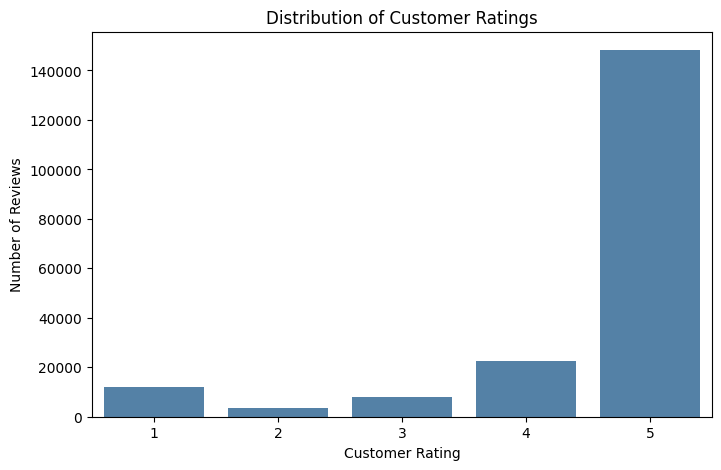

In [29]:

# Count the number of reviews for each rating
rating_counts = df['ratings'].value_counts().sort_index()

print(rating_counts)

# Visualize rating distribution
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='ratings', color='steelblue')

plt.title('Distribution of Customer Ratings')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Reviews')

plt.show()


In [30]:
# Calculate average rating
average_rating = df['ratings'].mean()

print("Average Customer Rating:", round(average_rating, 2))

Average Customer Rating: 4.5


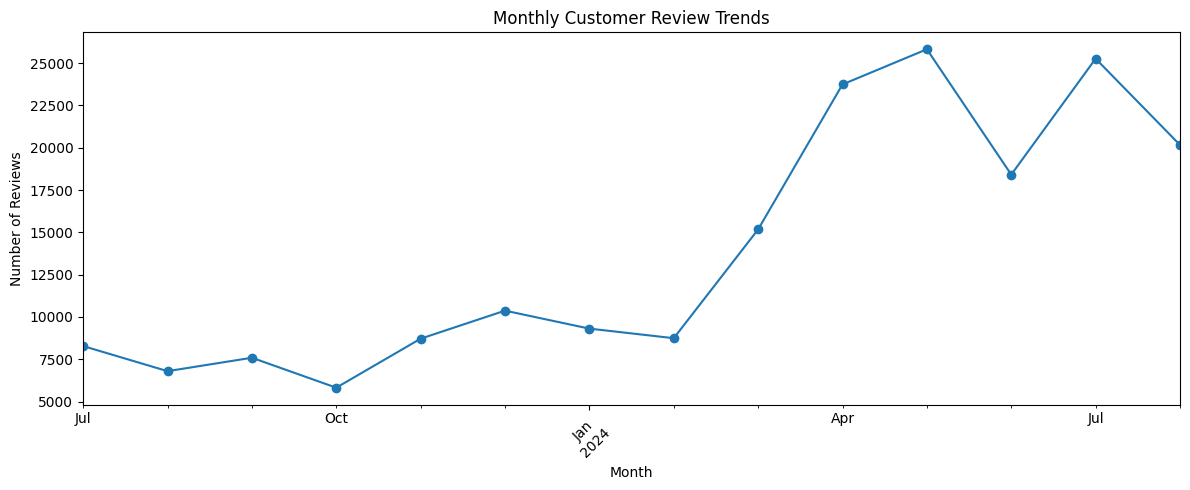

In [32]:
# Extract month and year
df['review_month'] = df['review_date'].dt.to_period('M')

# Count reviews per month
monthly_reviews = df.groupby('review_month').size()

# Visualize monthly review trends
plt.figure(figsize=(12,5))

monthly_reviews.plot(kind='line', marker='o')

plt.title('Monthly Customer Review Trends')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Average Review Length: 46.78


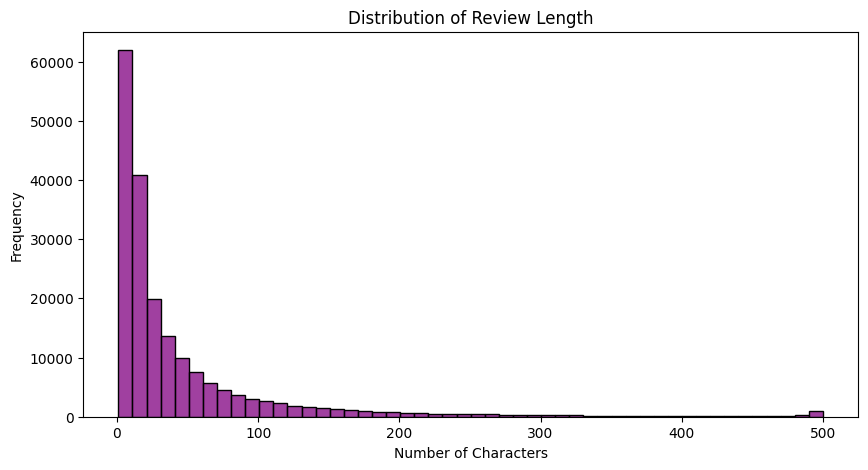

In [33]:
# Calculate number of characters in each review
df['review_length'] = df['review'].astype(str).apply(len)

# Calculate average review length
print("Average Review Length:", round(df['review_length'].mean(), 2))

# Visualize review length distribution
plt.figure(figsize=(10,5))

sns.histplot(df['review_length'], bins=50, color='purple')

plt.title('Distribution of Review Length')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')

plt.show()

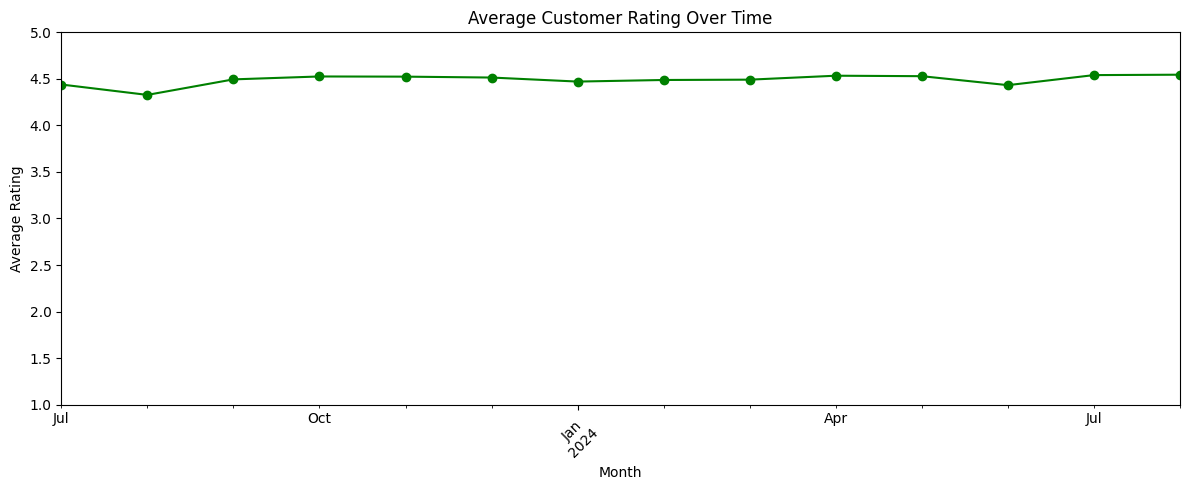

In [34]:
# Calculate average rating for each month
monthly_rating = df.groupby('review_month')['ratings'].mean()

# Plot monthly average rating
plt.figure(figsize=(12,5))

monthly_rating.plot(marker='o', color='green')

plt.title('Average Customer Rating Over Time')
plt.xlabel('Month')
plt.ylabel('Average Rating')

plt.ylim(1,5)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [35]:
print("EXPLORATORY DATA ANALYSIS SUMMARY")
print("---------------------------------")

print("Total Reviews:", len(df))

print("Average Rating:", round(df['ratings'].mean(), 2))

print("Highest Rating:", df['ratings'].max())

print("Lowest Rating:", df['ratings'].min())

print("Average Review Length:", round(df['review_length'].mean(), 2))

print("Most Common Rating:", df['ratings'].mode()[0])

EXPLORATORY DATA ANALYSIS SUMMARY
---------------------------------
Total Reviews: 194210
Average Rating: 4.5
Highest Rating: 5
Lowest Rating: 1
Average Review Length: 46.78
Most Common Rating: 5


Step 5 – Text Preprocessing and Sentiment Analysis

In [39]:

# Create a function to clean review text

def clean_review(text):
    text = str(text).lower()                  # Convert to lowercase
    text = re.sub(r'http\S+', '', text)       # Remove URLs
    text = re.sub(r'[^a-z\s]', '', text)      # Remove special characters and numbers
    text = re.sub(r'\s+', ' ', text).strip()  # Remove extra spaces
    return text

# Apply cleaning function
df['cleaned_review'] = df['review'].apply(clean_review)

# Display original and cleaned reviews
df[['review', 'cleaned_review']].head(20)


,review,cleaned_review
0,good,good
1,good,good
2,nice app,nice app
3,"nice, ig",nice ig
4,"this is a great app, the bot is so accurate to...",this is a great app the bot is so accurate to ...
5,so nice app,so nice app
6,"just love this app, or guy",just love this app or guy
7,great app,great app
8,Very impressive,very impressive
9,helps with coding a lot this ai is great for e...,helps with coding a lot this ai is great for e...


In [40]:

# Function to calculate polarity

def get_polarity(text):
    return TextBlob(str(text)).sentiment.polarity

# Apply polarity function to all reviews
df['polarity'] = df['review'].apply(get_polarity)

# Display results
df[['review', 'polarity']].head(10)


,review,polarity
0,good,0.7000
1,good,0.7000
2,nice app,0.6000
3,"nice, ig",0.6000
4,"this is a great app, the bot is so accurate to...",0.4125
5,so nice app,0.6000
6,"just love this app, or guy",0.5000
7,great app,0.8000
8,Very impressive,1.0000
9,helps with coding a lot this ai is great for e...,0.8000


In [41]:
# Function to calculate subjectivity

def get_subjectivity(text):
    return TextBlob(str(text)).sentiment.subjectivity

# Apply subjectivity function
df['subjectivity'] = df['review'].apply(get_subjectivity)

# Display results
df[['review', 'polarity', 'subjectivity']].head(10)

,review,polarity,subjectivity
0,good,0.7000,0.600000
1,good,0.7000,0.600000
2,nice app,0.6000,1.000000
3,"nice, ig",0.6000,1.000000
4,"this is a great app, the bot is so accurate to...",0.4125,0.542949
5,so nice app,0.6000,1.000000
6,"just love this app, or guy",0.5000,0.600000
7,great app,0.8000,0.750000
8,Very impressive,1.0000,1.000000
9,helps with coding a lot this ai is great for e...,0.8000,0.750000


In [42]:

# Function to classify sentiment

def classify_sentiment(score):
    if score > 0:
        return 'Positive'
    elif score < 0:
        return 'Negative'
    else:
        return 'Neutral'

# Apply classification
df['sentiment'] = df['polarity'].apply(classify_sentiment)

# Display classified reviews
df[['review', 'polarity', 'subjectivity', 'sentiment']].head(15)


,review,polarity,subjectivity,sentiment
0,good,0.700000,0.600000,Positive
1,good,0.700000,0.600000,Positive
2,nice app,0.600000,1.000000,Positive
3,"nice, ig",0.600000,1.000000,Positive
4,"this is a great app, the bot is so accurate to...",0.412500,0.542949,Positive
5,so nice app,0.600000,1.000000,Positive
6,"just love this app, or guy",0.500000,0.600000,Positive
7,great app,0.800000,0.750000,Positive
8,Very impressive,1.000000,1.000000,Positive
9,helps with coding a lot this ai is great for e...,0.800000,0.750000,Positive


In [43]:
# Count positive, negative and neutral reviews

sentiment_counts = df['sentiment'].value_counts()

print(sentiment_counts)

sentiment
Positive    148219
Neutral      37922
Negative      8069
Name: count, dtype: int64


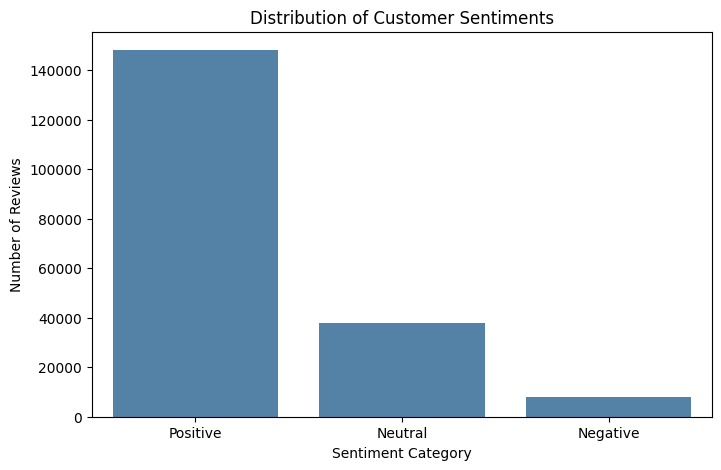

In [44]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='sentiment',
    order=['Positive', 'Neutral', 'Negative'],
    color='steelblue'
)

plt.title('Distribution of Customer Sentiments')
plt.xlabel('Sentiment Category')
plt.ylabel('Number of Reviews')

plt.show()

sentiment
Positive    76.32
Neutral     19.53
Negative     4.15
Name: proportion, dtype: float64


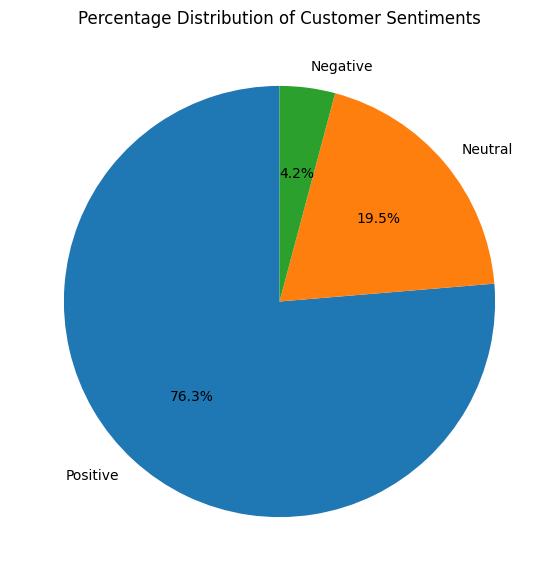

In [45]:
# Calculate sentiment percentages

sentiment_percentage = (
    df['sentiment'].value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

# Pie chart
plt.figure(figsize=(7,7))

plt.pie(
    sentiment_percentage,
    labels=sentiment_percentage.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Customer Sentiments')

plt.show()

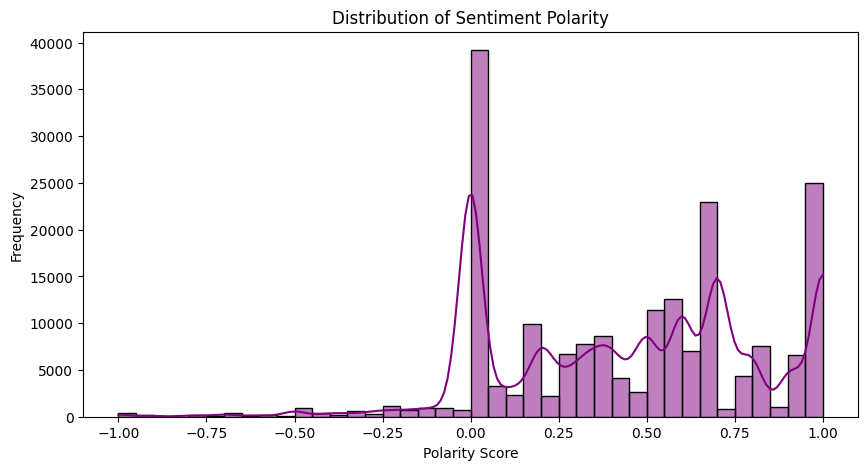

In [46]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='polarity',
    bins=40,
    kde=True,
    color='purple'
)

plt.title('Distribution of Sentiment Polarity')
plt.xlabel('Polarity Score')
plt.ylabel('Frequency')

plt.show()

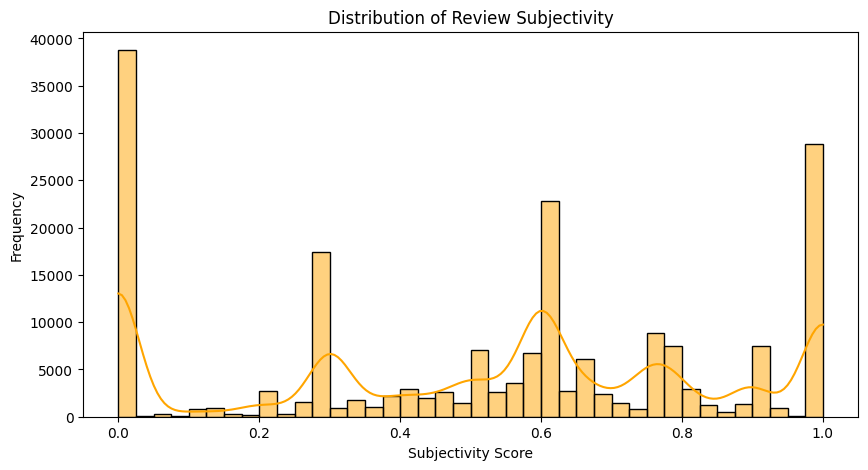

In [47]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='subjectivity',
    bins=40,
    kde=True,
    color='orange'
)

plt.title('Distribution of Review Subjectivity')
plt.xlabel('Subjectivity Score')
plt.ylabel('Frequency')

plt.show()

In [48]:
print("SENTIMENT ANALYSIS SUMMARY")
print("--------------------------")

print("Total Reviews:", len(df))

print("Average Polarity:",
      round(df['polarity'].mean(), 3))

print("Average Subjectivity:",
      round(df['subjectivity'].mean(), 3))

print("\nSentiment Counts:")
print(df['sentiment'].value_counts())

print("\nSentiment Percentages:")
print((df['sentiment'].value_counts(normalize=True) * 100).round(2))

SENTIMENT ANALYSIS SUMMARY
--------------------------
Total Reviews: 194210
Average Polarity: 0.447
Average Subjectivity: 0.517

Sentiment Counts:
sentiment
Positive    148219
Neutral      37922
Negative      8069
Name: count, dtype: int64

Sentiment Percentages:
sentiment
Positive    76.32
Neutral     19.53
Negative     4.15
Name: proportion, dtype: float64


Step 6 – Rating vs Sentiment Analysis.

In [51]:

# Calculate average polarity for each rating

rating_sentiment = df.groupby('ratings')['polarity'].mean()

print(rating_sentiment)


ratings
1    0.012753
2    0.157869
3    0.304388
4    0.424929
5    0.499483
Name: polarity, dtype: float64


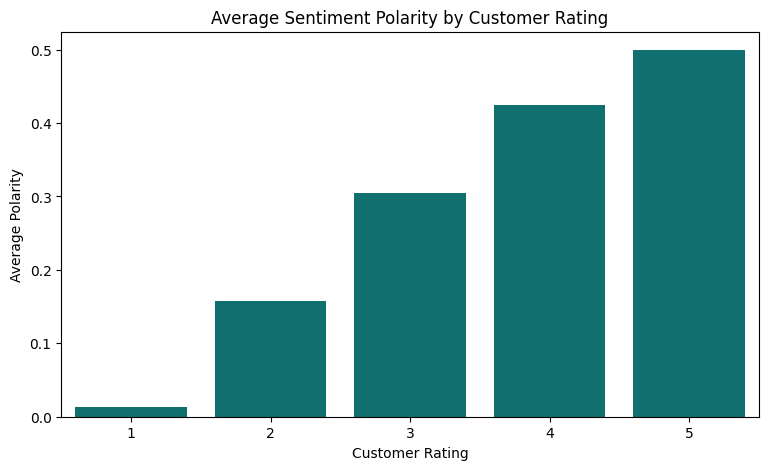

In [52]:

plt.figure(figsize=(9,5))

sns.barplot(
    x=rating_sentiment.index,
    y=rating_sentiment.values,
    color='teal'
)

plt.title('Average Sentiment Polarity by Customer Rating')
plt.xlabel('Customer Rating')
plt.ylabel('Average Polarity')

plt.show()


In [53]:
# Create a cross-tabulation
sentiment_rating = pd.crosstab(
    df['ratings'],
    df['sentiment']
)

print(sentiment_rating)

sentiment  Negative  Neutral  Positive
ratings                               
1              3563     4638      3762
2               707      971      1668
3               822     1911      5313
4               870     3956     17777
5              2107    26446    119699


<Figure size 1000x600 with 0 Axes>

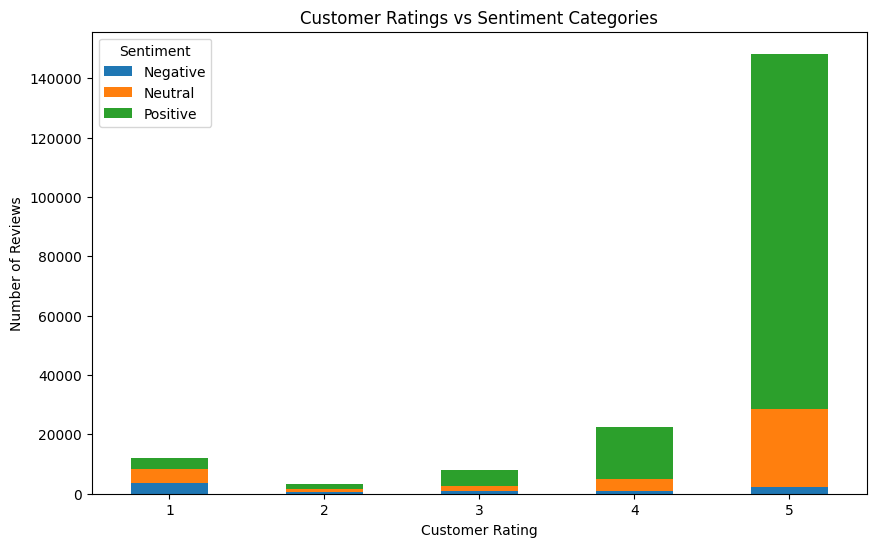

In [54]:
plt.figure(figsize=(10,6))

sentiment_rating.plot(
    kind='bar',
    stacked=True,
    figsize=(10,6)
)

plt.title('Customer Ratings vs Sentiment Categories')
plt.xlabel('Customer Rating')
plt.ylabel('Number of Reviews')

plt.xticks(rotation=0)
plt.legend(title='Sentiment')

plt.show()

In [55]:
# Calculate correlation between ratings and sentiment scores

correlation = df[['ratings', 'polarity', 'subjectivity']].corr()

print(correlation)

               ratings  polarity  subjectivity
ratings       1.000000  0.333787      0.114826
polarity      0.333787  1.000000      0.553471
subjectivity  0.114826  0.553471      1.000000


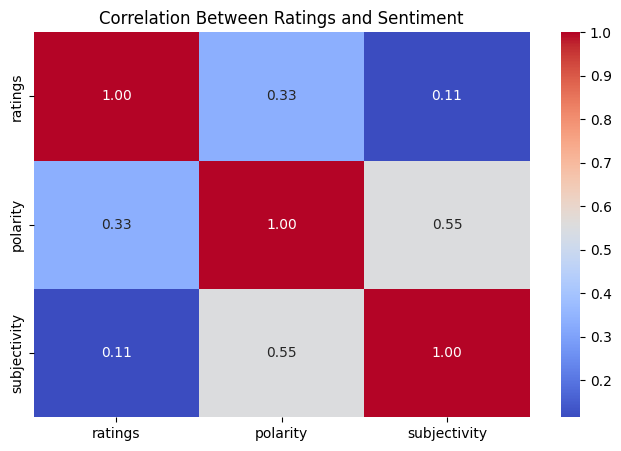

In [56]:
plt.figure(figsize=(8,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Ratings and Sentiment')

plt.show()

Step 7 – Positive and Negative Review Analysis

In [57]:
positive_reviews = df[df['ratings'].isin([4, 5])]

print("Total Positive Reviews:", len(positive_reviews))

positive_reviews[['review', 'ratings']].head(10)


Total Positive Reviews: 170855


,review,ratings
0,good,5
1,good,5
2,nice app,5
3,"nice, ig",5
4,"this is a great app, the bot is so accurate to...",5
5,so nice app,5
6,"just love this app, or guy",4
8,Very impressive,5
9,helps with coding a lot this ai is great for e...,5
11,good,4


In [58]:
negative_reviews = df[df['ratings'].isin([1, 2])]

print("Total Negative Reviews:", len(negative_reviews))

negative_reviews[['review', 'ratings']].head(10)

Total Negative Reviews: 15309


,review,ratings
7,great app,1
25,2024-08-23 Call function doesn't get language ...,2
70,"You must 3 add the crop feature to photo, bene...",2
72,How can i enter to this app??,1
95,- সুন্দর<3🩷🪽,2
98,has a lot of complains,2
115,Why does this app keep telling me an error has...,1
119,not good,1
121,good,2
134,Too expensive,1


Step 8 – Keyword Extraction and Text Analysis.

In [59]:

from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

# Define common words to exclude
stop_words = list(ENGLISH_STOP_WORDS)

print("Text analysis tools imported successfully!")


Text analysis tools imported successfully!


In [60]:

# Initialize CountVectorizer
vectorizer_positive = CountVectorizer(
    stop_words=stop_words,
    max_features=20
)

# Extract keywords
positive_matrix = vectorizer_positive.fit_transform(
    positive_reviews['cleaned_review']
)

# Calculate word frequencies
positive_word_counts = positive_matrix.sum(axis=0)

positive_words = pd.DataFrame({
    'Word': vectorizer_positive.get_feature_names_out(),
    'Frequency': positive_word_counts.A1
})

# Sort by frequency
positive_words = positive_words.sort_values(
    by='Frequency', ascending=False
)

display(positive_words)


,Word,Frequency
2,app,43756
8,good,35214
4,best,17627
16,nice,12776
10,great,11143
12,helpful,10970
0,ai,10481
6,chatgpt,8735
1,amazing,8358
15,love,8313


In [61]:

vectorizer_negative = CountVectorizer(
    stop_words=stop_words,
    max_features=20
)

negative_matrix = vectorizer_negative.fit_transform(
    negative_reviews['cleaned_review']
)

negative_word_counts = negative_matrix.sum(axis=0)

negative_words = pd.DataFrame({
    'Word': vectorizer_negative.get_feature_names_out(),
    'Frequency': negative_word_counts.A1
})

negative_words = negative_words.sort_values(
    by='Frequency', ascending=False
)

display(negative_words)


,Word,Frequency
2,app,4312
9,good,1685
16,use,1086
6,doesnt,1019
12,just,968
5,chatgpt,963
15,time,905
7,dont,893
0,ai,883
8,error,857


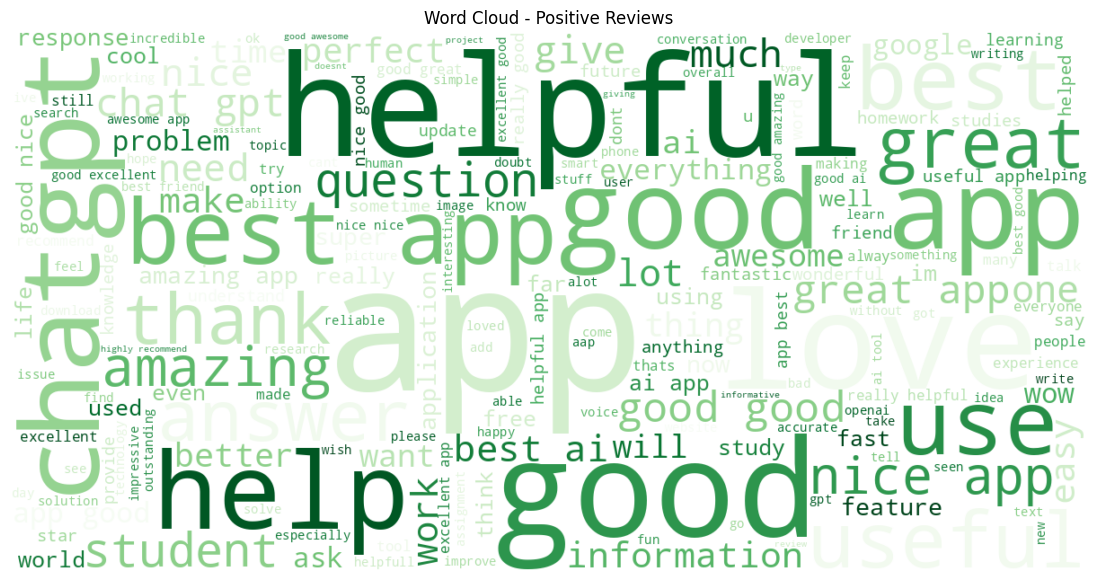

In [64]:
positive_text = ' '.join(positive_reviews['cleaned_review'])

positive_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='Greens'
).generate(positive_text)

plt.figure(figsize=(14,7))

plt.imshow(positive_wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Word Cloud - Positive Reviews')

plt.show()

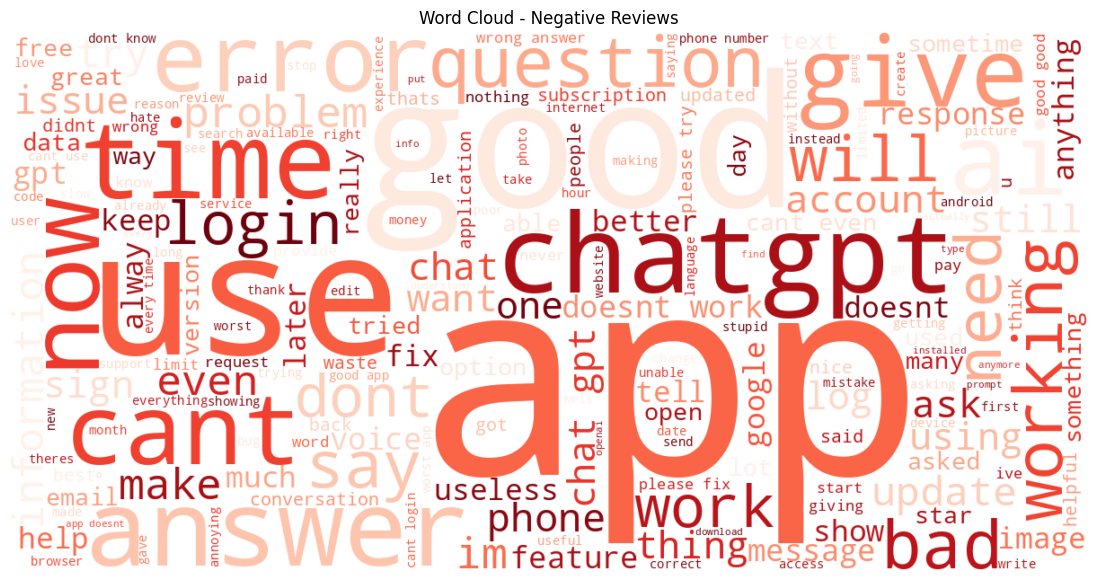

In [65]:
negative_text = ' '.join(negative_reviews['cleaned_review'])

negative_wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='Reds'
).generate(negative_text)

plt.figure(figsize=(14,7))

plt.imshow(negative_wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Word Cloud - Negative Reviews')

plt.show()

In [66]:

print("CHATGPT REVIEW ANALYSIS - FINAL REPORT")
print("=" * 45)

print("Total Reviews:", len(df))

print("Average Customer Rating:",
      round(df['ratings'].mean(), 2), "/ 5")

print("Average Sentiment Polarity:",
      round(df['polarity'].mean(), 3))

print("Average Subjectivity:",
      round(df['subjectivity'].mean(), 3))

print("\nSentiment Distribution:")

print((df['sentiment'].value_counts(normalize=True) * 100).round(2))

print("\nMost Common Positive Keywords:")
print(positive_words.head(5))

print("\nMost Common Negative Keywords:")
print(negative_words.head(5))


CHATGPT REVIEW ANALYSIS - FINAL REPORT
Total Reviews: 194210
Average Customer Rating: 4.5 / 5
Average Sentiment Polarity: 0.447
Average Subjectivity: 0.517

Sentiment Distribution:
sentiment
Positive    76.32
Neutral     19.53
Negative     4.15
Name: proportion, dtype: float64

Most Common Positive Keywords:
     Word  Frequency
2     app      43756
8    good      35214
4    best      17627
16   nice      12776
10  great      11143

Most Common Negative Keywords:
      Word  Frequency
2      app       4312
9     good       1685
16     use       1086
6   doesnt       1019
12    just        968


In [67]:
# Export analyzed dataset to CSV

df.to_csv('ChatGPT_Review_Analysis_Final.csv', index=False)

print("Final dataset exported successfully!")

Final dataset exported successfully!


## Conclusion

This project analyzed customer reviews of ChatGPT using Python, Natural Language Processing (NLP), and data visualization techniques.

The analysis involved data cleaning, exploratory data analysis, sentiment polarity calculation, subjectivity analysis, sentiment classification, and keyword extraction.

The sentiment analysis helped categorize customer feedback into positive, neutral, and negative sentiments. Keyword extraction and word cloud visualizations provided insights into frequently discussed aspects of the ChatGPT application.

The project demonstrates how customer reviews can be transformed into meaningful information that helps understand user satisfaction and identify areas requiring improvement.

### Limitations

- TextBlob may not accurately identify sarcasm or context-dependent expressions.
- Keyword frequency does not always indicate whether a feature is praised or criticized.
- Automated sentiment classification may produce incorrect classifications.
- The dataset represents the available reviews and may not reflect every ChatGPT user's experience.

### Future Scope

Further analysis could include advanced NLP models, aspect-based sentiment analysis, and machine learning techniques to improve sentiment classification accuracy.